# Train a small custom CNN for tomato leaf classification

Run each cell from top to bottom using **Shift + Enter**, or use **Run → Run All Cells**.
Choose the **Python (LeafCheck)** kernel. The notebook trains a CNN with newly
initialized weights using the original prepared `data/processed/leafcheck` folders.

The first experiment fits 12 training images to check the learning pipeline.
The second starts with a fresh model, trains on 120 images, and selects a checkpoint
using loss on 460 validation images. The final cells restore that checkpoint,
verify its predictions, display validation metrics, and provide image prediction.

Each pilot run creates its own folder under `runs/leafcheck_small/`. The saved
metrics describe validation performance used for model selection. Held-out test
evaluation belongs after development decisions are complete.

To install dependencies from a terminal, activate `.venv`, then run
`python -m pip install -r requirements.txt`. Launch with `python -m jupyterlab`
from the project root.

## 1. Environment and experiment settings

Change settings here before running the notebook again. `SEED` controls the random
sampling and initialization. `TINY_UPDATES` is the number of updates to the same
12 images. `EPOCHS` is the maximum number of passes over the 120-image pilot.
Early stopping ends the pilot after five consecutive epochs without a lower
validation loss. Increase `TINY_UPDATES` to 300 if the tiny-set loss is still falling.

`DEVICE_PREFERENCE = "auto"` selects MPS on a supported Mac and CPU otherwise.
Set it to `"cpu"` to investigate an accelerator error. Seeds improve repeatability,
while results can still vary across software versions and devices.

In [1]:
import csv
import hashlib
import json
import random
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchvision
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.transforms.functional import to_tensor

PROJECT_ROOT = Path.cwd().resolve()
DATA_ROOT = PROJECT_ROOT / "data/processed/leafcheck"
SEED = 434
INPUT_SIZE = 128
TINY_PER_CLASS = 4
PILOT_PER_CLASS = 40
TINY_UPDATES = 100
BATCH_SIZE = 16
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
DROPOUT = 0.2
EPOCHS = 10
PATIENCE = 5
DEVICE_PREFERENCE = "auto"

assert (DATA_ROOT / "train").is_dir(), (
    "Set PROJECT_ROOT to your ML-Final-Project folder, then run from this cell again."
)
assert DEVICE_PREFERENCE in {"auto", "cpu", "mps"}

def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
if DEVICE_PREFERENCE == "auto":
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
else:
    device = torch.device(DEVICE_PREFERENCE)

environment = {
    "python": sys.version,
    "python_executable": sys.executable,
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "pillow": Image.__version__,
    "device": str(device),
}
print(json.dumps(environment, indent=2))
print("Device calculation:", torch.ones(2, device=device) + 1)

{
  "python": "3.14.7 (main, Aug  5 2026, 10:29:49) [Clang 21.0.0 (clang-2100.1.1.101)]",
  "python_executable": "/Users/jacobamey/Desktop/Brockport_Class/ML-Final-Project/.venv/bin/python",
  "torch": "2.15.0",
  "torchvision": "0.29.2",
  "pillow": "13.0.0",
  "device": "mps"
}
Device calculation: tensor([2., 2.], device='mps:0')


## 2. Load images with shared preprocessing

The loader corrects EXIF orientation, converts to RGB, resizes without changing
proportions, adds neutral gray padding where needed, and converts byte pixels
to a float32 tensor in [0, 1]. The same function prepares every image in this
notebook, including predictions. These baseline experiments use deterministic
preprocessing throughout.

In [2]:
def load_leaf(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = ImageOps.pad(
            image,
            (INPUT_SIZE, INPUT_SIZE),
            method=Image.Resampling.BILINEAR,
            color=(128, 128, 128),
        )
        return to_tensor(image)

train_data = ImageFolder(DATA_ROOT / "train", loader=load_leaf)
validation_data = ImageFolder(DATA_ROOT / "validation", loader=load_leaf)
expected_mapping = {"early_blight": 0, "healthy": 1, "late_blight": 2}
assert train_data.class_to_idx == validation_data.class_to_idx == expected_mapping
class_names = train_data.classes

example, example_label = train_data[0]
assert example.shape == (3, INPUT_SIZE, INPUT_SIZE)
assert example.dtype == torch.float32
assert 0 <= example.min().item() <= example.max().item() <= 1
print("Training images available:", len(train_data))
print("Validation images:", len(validation_data))
print("Class order:", class_names)
print("Example shape and label:", example.shape, example_label)

Training images available: 1847
Validation images: 460
Class order: ['early_blight', 'healthy', 'late_blight']
Example shape and label: torch.Size([3, 128, 128]) 0


## 3. Choose balanced training subsets and inspect a batch

Each subset is sampled from the existing training folder. `Subset` stores image
positions and uses the original loader. Sampling preserves the existing split
assignments. Multiple selected images can show the same leaf.

The inventory check below verifies the recorded leaf groups and file hashes for
the selected training and validation files. The split audit documents the remaining
limits of grouping. It is available in `data/README.md`.

Tiny and pilot image counts: 12 120
Batch shapes: torch.Size([12, 3, 128, 128]) torch.Size([12])
Recorded training and validation groups are disjoint.


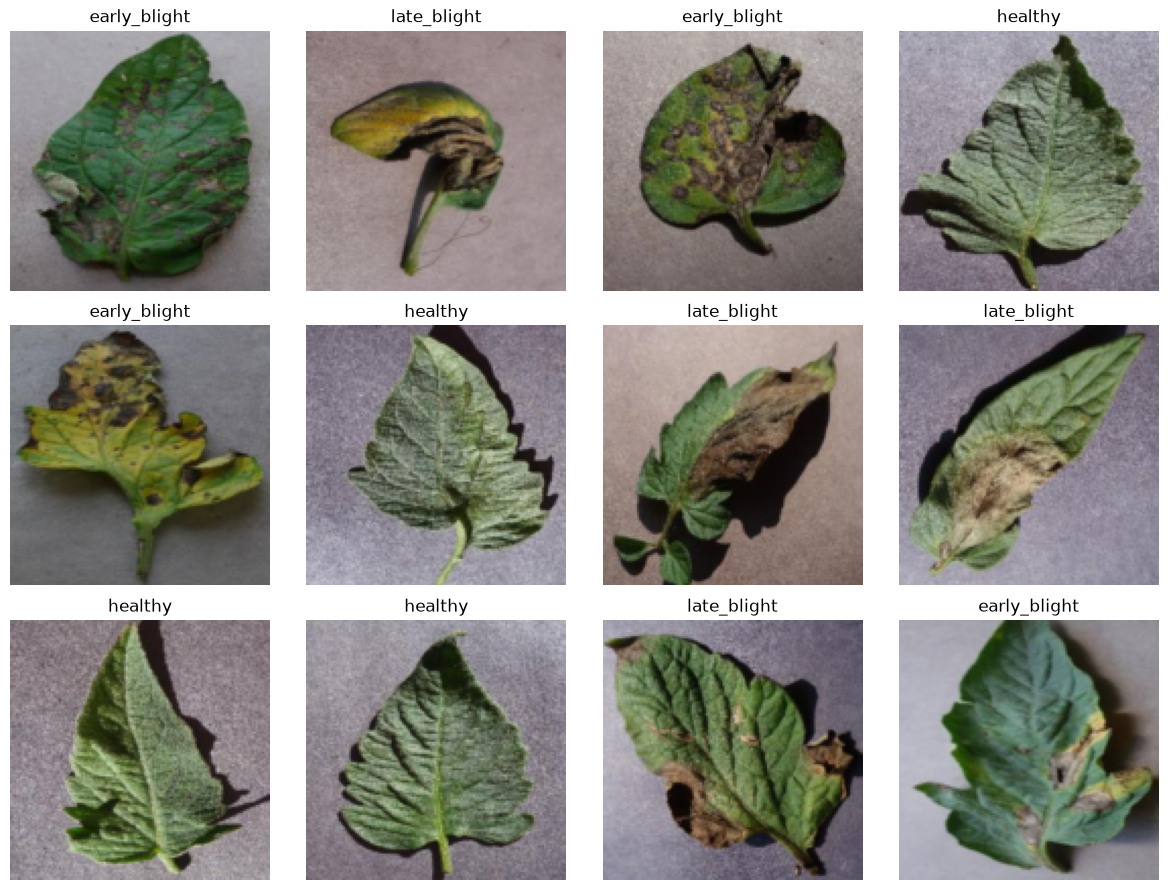

In [3]:
def balanced_subset(dataset, per_class, seed):
    rng = random.Random(seed)
    selected = []
    for class_index in range(len(dataset.classes)):
        candidates = [
            index for index, label in enumerate(dataset.targets)
            if label == class_index
        ]
        selected.extend(rng.sample(candidates, per_class))
    return Subset(dataset, selected)

tiny_train = balanced_subset(train_data, TINY_PER_CLASS, SEED)
pilot_train = balanced_subset(train_data, PILOT_PER_CLASS, SEED)

with (PROJECT_ROOT / "data/manifests/image_inventory.csv").open(newline="") as file:
    inventory = {
        str((PROJECT_ROOT / row["image_path"]).resolve()): row
        for row in csv.DictReader(file)
        if row["status"] == "included"
    }

selection_rows = []
for selection, dataset, indices in [
    ("tiny_train", train_data, tiny_train.indices),
    ("pilot_train", train_data, pilot_train.indices),
    ("validation", validation_data, range(len(validation_data))),
]:
    expected_split = "validation" if selection == "validation" else "train"
    for index in indices:
        path, target = dataset.samples[index]
        path = Path(path).resolve()
        row = inventory[str(path)]
        assert row["split"] == expected_split and row["group_id"]
        assert row["project_label"] == class_names[target]
        assert hashlib.sha256(path.read_bytes()).hexdigest() == row["sha256"]
        selection_rows.append({
            "selection": selection,
            "image_path": path.relative_to(PROJECT_ROOT).as_posix(),
            "class_name": class_names[target],
            "class_index": target,
            "group_id": row["group_id"],
            "sha256": row["sha256"],
        })

train_groups = {r["group_id"] for r in selection_rows if r["selection"] != "validation"}
validation_groups = {r["group_id"] for r in selection_rows if r["selection"] == "validation"}
train_hashes = {r["sha256"] for r in selection_rows if r["selection"] != "validation"}
validation_hashes = {r["sha256"] for r in selection_rows if r["selection"] == "validation"}
assert train_groups.isdisjoint(validation_groups)
assert train_hashes.isdisjoint(validation_hashes)

tiny_loader = DataLoader(
    tiny_train, batch_size=len(tiny_train), shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
images, labels = next(iter(tiny_loader))
assert images.shape == (12, 3, INPUT_SIZE, INPUT_SIZE)
assert labels.dtype == torch.long
assert torch.bincount(labels, minlength=3).tolist() == [4, 4, 4]
print("Tiny and pilot image counts:", len(tiny_train), len(pilot_train))
print("Batch shapes:", images.shape, labels.shape)
print("Recorded training and validation groups are disjoint.")

figure, axes = plt.subplots(3, 4, figsize=(12, 9))
for axis, image, label in zip(axes.flat, images, labels):
    axis.imshow(image.permute(1, 2, 0))
    axis.set_title(class_names[label.item()])
    axis.axis("off")
figure.tight_layout()
plt.show()

## 4. Define the custom CNN

Each constructor call creates new convolution and linear weights using PyTorch's
default random initialization. The three blocks use 3 × 3 convolutions with padding
1 and stride 1. Each 2 × 2 max pool halves height and width. Batch normalization
learns a scale and offset and tracks feature statistics. ReLU adds nonlinearity.

| Component | Output shape |
| --- | --- |
| Input | B × 3 × 128 × 128 |
| Block 1 | B × 16 × 64 × 64 |
| Block 2 | B × 32 × 32 × 32 |
| Block 3 | B × 64 × 16 × 16 |
| Global average pooling and flatten | B × 64 |
| Dropout and linear output | B × 3 |

The final outputs are raw logits. Cross-entropy consumes these scores directly.
Softmax is applied once in the prediction function when displaying class scores.

In [4]:
class PlantCNN(nn.Module):
    def __init__(self, num_classes=3, dropout=0.2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(start_dim=1),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))

## 5. Verify one forward pass and one parameter update

`backward()` computes gradients. `optimizer.step()` changes parameters. The
before-and-after check uses a cloned tensor so it preserves the old values.
This diagnostic model is local to the function. The following experiments each
construct another fresh model.

In [5]:
def check_one_update(images, labels):
    set_seed(SEED)
    model = PlantCNN(len(class_names), dropout=0.0).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.0)
    loss_fn = nn.CrossEntropyLoss()
    batch_images, batch_labels = images.to(device), labels.to(device)

    model.eval()
    with torch.no_grad():
        logits = model(batch_images)
    assert logits.shape == (len(labels), len(class_names))
    parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert parameter_count == 23891

    before = model.features[0].weight.detach().clone()
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(batch_images), batch_labels)
    assert torch.isfinite(loss).item()
    loss.backward()
    gradient = model.features[0].weight.grad
    assert gradient is not None and torch.isfinite(gradient).all().item()
    optimizer.step()
    change = (model.features[0].weight.detach() - before).abs().max().item()
    assert change > 0
    print("Output shape:", logits.shape)
    print("Trainable parameters:", parameter_count)
    print("Finite training loss:", loss.item())
    print("Maximum first-layer weight change:", change)

check_one_update(images, labels)

Output shape: torch.Size([12, 3])
Trainable parameters: 23891
Finite training loss: 1.1284617185592651
Maximum first-layer weight change: 0.0010000020265579224


## 6. Training and evaluation functions

Training enables dropout and updates batch-normalization statistics. Evaluation
disables dropout and uses stored statistics. `torch.no_grad()` also disables
gradient tracking during evaluation.

Loss is averaged across examples by weighting each batch mean by its size.
Accuracy is the fraction correct. Macro F1 averages the three class F1 scores
equally. Precision and recall use zero when their denominator is zero. The
confusion matrix uses actual classes as rows and predicted classes as columns.

In [6]:
def classification_metrics(targets, predictions):
    number_of_classes = len(class_names)
    matrix = torch.bincount(
        targets * number_of_classes + predictions,
        minlength=number_of_classes ** 2,
    ).reshape(number_of_classes, number_of_classes)

    true_positive = matrix.diag().float()
    support = matrix.sum(dim=1)
    precision = true_positive / matrix.sum(dim=0).clamp_min(1)
    recall = true_positive / support.clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
    return {
        "accuracy": true_positive.sum().item() / targets.numel(),
        "macro_f1": f1.mean().item(),
        "confusion_matrix": matrix.tolist(),
        "per_class": [
            {
                "class_name": name,
                "precision": precision[index].item(),
                "recall": recall[index].item(),
                "f1": f1[index].item(),
                "support": support[index].item(),
            }
            for index, name in enumerate(class_names)
        ],
    }

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad()
        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)
        if not torch.isfinite(loss).item():
            raise RuntimeError("Training loss is nonfinite. Check inputs and learning rate.")
        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total_examples += batch_size
    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
    }

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    targets, predictions = [], []
    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)
        if not torch.isfinite(loss).item():
            raise RuntimeError("Evaluation loss is nonfinite.")
        total_loss += loss.item() * batch_labels.size(0)
        targets.append(batch_labels.cpu())
        predictions.append(logits.argmax(dim=1).cpu())
    targets = torch.cat(targets)
    metrics = classification_metrics(targets, torch.cat(predictions))
    metrics["loss"] = total_loss / targets.numel()
    return metrics

## 7. Fit the same 12 images

Dropout and weight decay are zero for this pipeline check. Every update uses all
12 images. Every tenth update measures those same images in evaluation mode.
Compare the recorded loss and number correct over time. A successful fit provides
evidence that the pipeline learns training examples. Validation follows in the pilot.

Update  10 | loss 1.0888 | correct 4/12
Update  20 | loss 1.9785 | correct 4/12
Update  30 | loss 2.7022 | correct 4/12
Update  40 | loss 2.5970 | correct 4/12
Update  50 | loss 1.6667 | correct 7/12
Update  60 | loss 0.7488 | correct 8/12
Update  70 | loss 0.0869 | correct 12/12
Update  80 | loss 0.0280 | correct 12/12
Update  90 | loss 0.0176 | correct 12/12
Update 100 | loss 0.0128 | correct 12/12


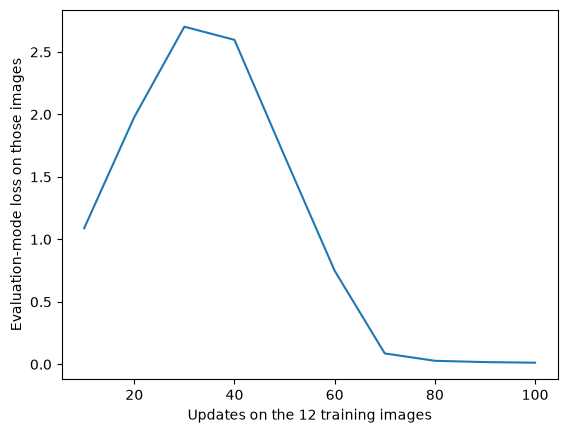

In [7]:
def run_tiny_check():
    set_seed(SEED)
    tiny_model = PlantCNN(len(class_names), dropout=0.0).to(device)
    optimizer = torch.optim.AdamW(
        tiny_model.parameters(), lr=LEARNING_RATE, weight_decay=0.0,
    )
    loss_fn = nn.CrossEntropyLoss()
    batch_images, batch_labels = images.to(device), labels.to(device)
    history = []

    for update in range(1, TINY_UPDATES + 1):
        tiny_model.train()
        optimizer.zero_grad()
        loss = loss_fn(tiny_model(batch_images), batch_labels)
        assert torch.isfinite(loss).item()
        loss.backward()
        optimizer.step()

        if update % 10 == 0 or update == TINY_UPDATES:
            tiny_model.eval()
            with torch.no_grad():
                logits = tiny_model(batch_images)
                checked_loss = loss_fn(logits, batch_labels).item()
                correct = (logits.argmax(dim=1) == batch_labels).sum().item()
            history.append({"update": update, "loss": checked_loss, "correct": correct})
            print(f"Update {update:3d} | loss {checked_loss:.4f} | correct {correct}/12")
    return history

tiny_history = run_tiny_check()
plt.plot([row["update"] for row in tiny_history], [row["loss"] for row in tiny_history])
plt.xlabel("Updates on the 12 training images")
plt.ylabel("Evaluation-mode loss on those images")
plt.show()

## 8. Train the pilot and save the best checkpoint

This cell starts a fresh model and creates a new run folder each time it executes.
Training accuracy below is accumulated in training mode. Validation is measured
after each epoch in evaluation mode. Select the checkpoint with lowest validation
loss. Write the epoch log after every completed epoch.

The checkpoint contains a snapshot of the model weights, configuration, class order,
and reference logits for the same fixed validation batch. The temporary checkpoint
is renamed only after saving succeeds. This supports the reload check below.

In [8]:
set_seed(SEED)
pilot_loader = DataLoader(
    pilot_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
validation_loader = DataLoader(
    validation_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
reference_images, _ = next(iter(validation_loader))
model = PlantCNN(len(class_names), dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
loss_fn = nn.CrossEntropyLoss()

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
run_dir = PROJECT_ROOT / "runs/leafcheck_small" / run_id
run_dir.mkdir(parents=True, exist_ok=False)
checkpoint_path = run_dir / "best_model.pt"
config = {
    "model_version": "leafcheck-small-v1",
    "seed": SEED,
    "input_size": INPUT_SIZE,
    "train_images": len(pilot_train),
    "validation_images": len(validation_data),
    "tiny_updates": TINY_UPDATES,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "max_epochs": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "checkpoint_selection": "minimum validation loss",
    "preprocessing": "EXIF transpose, RGB, bilinear pad to square with RGB 128, tensor /255",
    "augmentation": "none",
    "environment": environment,
}
(run_dir / "config.json").write_text(json.dumps(config, indent=2))
(run_dir / "class_to_idx.json").write_text(json.dumps(train_data.class_to_idx, indent=2))
with (run_dir / "selected_images.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(selection_rows[0]))
    writer.writeheader()
    writer.writerows(selection_rows)
with (run_dir / "tiny_history.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(tiny_history[0]))
    writer.writeheader()
    writer.writerows(tiny_history)

history = []
best_loss = float("inf")
epochs_without_improvement = 0
print("Run folder:", run_dir)
for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()
    training = train_one_epoch(model, pilot_loader, loss_fn, optimizer)
    validation = evaluate(model, validation_loader, loss_fn)
    row = {
        "epoch": epoch,
        "train_loss": training["loss"],
        "train_accuracy": training["accuracy"],
        "validation_loss": validation["loss"],
        "validation_accuracy": validation["accuracy"],
        "validation_macro_f1": validation["macro_f1"],
        "seconds": time.perf_counter() - started,
    }
    history.append(row)
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)

    print(
        f"Epoch {epoch:2d}/{EPOCHS} | train loss {training['loss']:.4f} "
        f"acc {training['accuracy']:.1%} | val loss {validation['loss']:.4f} "
        f"acc {validation['accuracy']:.1%} F1 {validation['macro_f1']:.3f} "
        f"| {row['seconds']:.1f}s"
    )
    if validation["loss"] < best_loss:
        best_loss = validation["loss"]
        epochs_without_improvement = 0
        with torch.no_grad():
            reference_logits = model(reference_images.to(device)).cpu().clone()
        checkpoint = {
            "model_state_dict": {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            },
            "classes": class_names,
            "model_config": {"num_classes": len(class_names), "dropout": DROPOUT},
            "input_size": INPUT_SIZE,
            "epoch": epoch,
            "validation_loss": best_loss,
            "reference_logits": reference_logits,
            "config": config,
        }
        temporary_path = checkpoint_path.with_suffix(".tmp")
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(checkpoint_path)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping after consecutive epochs without lower validation loss.")
            break

Run folder: /Users/jacobamey/Desktop/Brockport_Class/ML-Final-Project/runs/leafcheck_small/20261115T223144_816768Z
Epoch  1/10 | train loss 0.9842 acc 53.3% | val loss 1.0983 acc 33.9% F1 0.169 | 0.8s
Epoch  2/10 | train loss 0.7161 acc 74.2% | val loss 1.1511 acc 33.9% F1 0.169 | 0.6s
Epoch  3/10 | train loss 0.6641 acc 75.0% | val loss 1.2405 acc 33.9% F1 0.169 | 0.6s
Epoch  4/10 | train loss 0.5584 acc 80.8% | val loss 1.2353 acc 33.9% F1 0.169 | 0.6s
Epoch  5/10 | train loss 0.5389 acc 83.3% | val loss 1.1722 acc 35.2% F1 0.196 | 0.6s
Epoch  6/10 | train loss 0.4990 acc 85.0% | val loss 0.9284 acc 40.9% F1 0.310 | 0.6s
Epoch  7/10 | train loss 0.4261 acc 87.5% | val loss 0.8543 acc 46.7% F1 0.413 | 0.6s
Epoch  8/10 | train loss 0.4457 acc 85.0% | val loss 0.5638 acc 80.7% F1 0.807 | 0.6s
Epoch  9/10 | train loss 0.4481 acc 84.2% | val loss 0.6852 acc 68.5% F1 0.691 | 0.6s
Epoch 10/10 | train loss 0.4184 acc 85.0% | val loss 0.5372 acc 73.3% F1 0.697 | 0.6s


## 9. Restore the selected model and verify its predictions

A checkpoint contains weights and metadata. The `PlantCNN` definition supplies the
architecture. Load the weights into a fresh instance and set evaluation mode.
Compare its logits with those saved at the selected epoch. The tolerance accounts
for small floating-point differences. This is a check of saving and restoring.

In [9]:
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["classes"] == class_names
assert checkpoint["input_size"] == INPUT_SIZE
restored_model = PlantCNN(**checkpoint["model_config"]).to(device)
restored_model.load_state_dict(checkpoint["model_state_dict"])
restored_model.eval()
with torch.no_grad():
    restored_logits = restored_model(reference_images.to(device)).cpu()
torch.testing.assert_close(
    restored_logits, checkpoint["reference_logits"], rtol=1e-4, atol=1e-5,
)
print("Checkpoint prediction comparison passed.")

validation_metrics = evaluate(restored_model, validation_loader, loss_fn)
selected_row = next(row for row in history if row["epoch"] == checkpoint["epoch"])
assert abs(validation_metrics["loss"] - selected_row["validation_loss"]) < 1e-5
assert validation_metrics["accuracy"] == selected_row["validation_accuracy"]
print("Selected epoch:", checkpoint["epoch"])
print(f"Validation loss: {validation_metrics['loss']:.4f}")
print(f"Validation accuracy: {validation_metrics['accuracy']:.1%}")
print(f"Validation macro F1: {validation_metrics['macro_f1']:.3f}")
for row in validation_metrics["per_class"]:
    print(
        f"{row['class_name']:14s} | precision {row['precision']:.3f} "
        f"recall {row['recall']:.3f} F1 {row['f1']:.3f} | count {row['support']}"
    )
validation_metrics["selected_epoch"] = checkpoint["epoch"]
(run_dir / "validation_metrics.json").write_text(json.dumps(validation_metrics, indent=2))

Checkpoint prediction comparison passed.
Selected epoch: 10
Validation loss: 0.5372
Validation accuracy: 73.3%
Validation macro F1: 0.697
early_blight   | precision 0.576 recall 0.904 F1 0.703 | count 156
healthy        | precision 0.957 recall 0.987 F1 0.972 | count 156
late_blight    | precision 0.778 recall 0.284 F1 0.416 | count 148


823

## 10. Plot learning curves and the validation confusion matrix

Compare the trends in both loss curves. Falling training loss with rising validation
loss suggests overfitting. A confusion matrix shows which classes are confused.
Macro F1 and per-class scores complement accuracy. These validation results were
used during model selection and should be identified as such in your report.

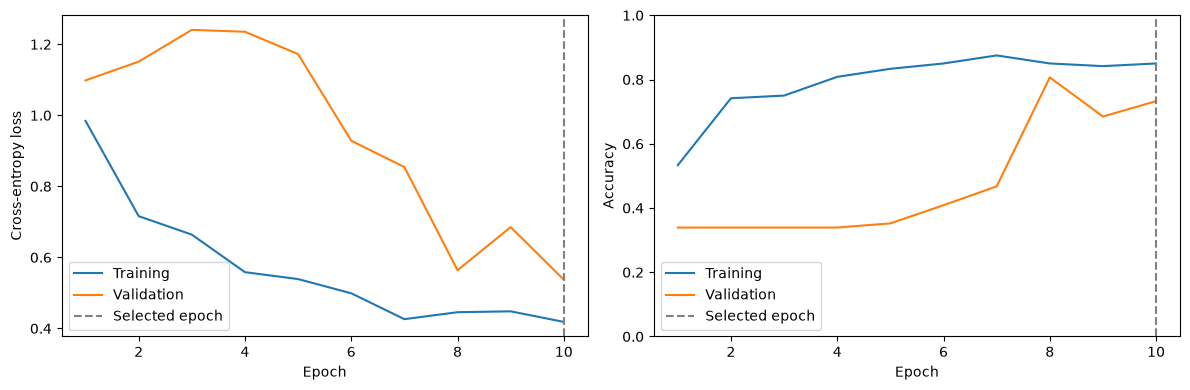

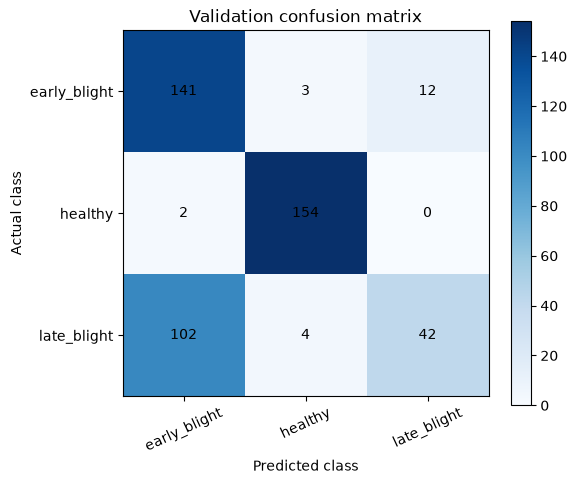

In [10]:
epochs = [row["epoch"] for row in history]
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, [row["train_loss"] for row in history], label="Training")
axes[0].plot(epochs, [row["validation_loss"] for row in history], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].plot(epochs, [row["train_accuracy"] for row in history], label="Training")
axes[1].plot(epochs, [row["validation_accuracy"] for row in history], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
for axis in axes:
    axis.axvline(checkpoint["epoch"], color="gray", linestyle="--", label="Selected epoch")
    axis.legend()
figure.tight_layout()
figure.savefig(run_dir / "learning_curves.png", dpi=160)
plt.show()

matrix = validation_metrics["confusion_matrix"]
figure, axis = plt.subplots(figsize=(6, 5))
heatmap = axis.imshow(matrix, cmap="Blues")
figure.colorbar(heatmap, ax=axis)
axis.set_xticks(range(len(class_names)), labels=class_names, rotation=25)
axis.set_yticks(range(len(class_names)), labels=class_names)
axis.set(xlabel="Predicted class", ylabel="Actual class", title="Validation confusion matrix")
for actual in range(len(class_names)):
    for predicted in range(len(class_names)):
        axis.text(predicted, actual, str(matrix[actual][predicted]), ha="center", va="center")
figure.tight_layout()
figure.savefig(run_dir / "validation_confusion_matrix.png", dpi=160)
plt.show()

## 11. Predict one image with the restored model

`unsqueeze(0)` adds the batch dimension to one preprocessed image. Softmax converts
the three logits into scores summing to one. A large score can accompany an incorrect
prediction, including for unfamiliar inputs. The classifier supports only its three
tomato categories and is a research prototype for classification.

The example below uses a validation image and prints its known label for comparison.
Replace `example_path` with an image path to try another input.

In [11]:
@torch.no_grad()
def predict_image(path, model, classes):
    model.eval()
    image = load_leaf(path).unsqueeze(0).to(device)
    probabilities = model(image).softmax(dim=1)[0].cpu()
    index = probabilities.argmax().item()
    return {
        "model_version": checkpoint["config"]["model_version"],
        "label": classes[index],
        "score": probabilities[index].item(),
        "class_scores": {
            name: probabilities[position].item()
            for position, name in enumerate(classes)
        },
    }

example_path, expected_index = validation_data.samples[0]
print("Source label:", class_names[expected_index])
print(json.dumps(predict_image(example_path, restored_model, checkpoint["classes"]), indent=2))
print("Model size in KiB:", round(checkpoint_path.stat().st_size / 1024, 1))
print("All pilot outputs:", run_dir)

Source label: early_blight
{
  "model_version": "leafcheck-small-v1",
  "label": "early_blight",
  "score": 0.8573846220970154,
  "class_scores": {
    "early_blight": 0.8573846220970154,
    "healthy": 0.023841053247451782,
    "late_blight": 0.11877428740262985
  }
}
Model size in KiB: 102.2
All pilot outputs: /Users/jacobamey/Desktop/Brockport_Class/ML-Final-Project/runs/leafcheck_small/20261115T223144_816768Z


## Review your work

Save the executed notebook. The run folder contains `best_model.pt`, `config.json`,
`class_to_idx.json`, `selected_images.csv`, `tiny_history.csv`, `history.csv`,
`validation_metrics.json`, `learning_curves.png`, and `validation_confusion_matrix.png`.

Explain what changes between the 12-image check and the pilot, how class order is
preserved, why the checkpoint is chosen using validation loss, and what the curves
show. Record the implementation assistance you used according to your course policy.
The architecture and training code in this notebook were supplied with AI assistance.

After understanding this run, change one major setting at a time and record your
hypothesis. To expand training, replace the `pilot_train` selection with
`pilot_train = Subset(train_data, list(range(len(train_data))))` and keep the existing
validation split. This preserves the index list used by the audit and selection records. Final testing uses the held-out internal
and external sets after selecting the model and settings.

Official references include the [PyTorch optimization tutorial](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html),
[cross-entropy documentation](https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html),
[saving and loading guide](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html),
and [reproducibility notes](https://docs.pytorch.org/docs/2.15/notes/randomness.html).